Fo_ref = Dref * tc / L2
Fo_heat = alfa * tc / L2 where alfa = k/(rho x cp)
Ev = deltaH * rho * L2 / (k * tc * (Tair - T0))

What is needed: Bed depth, dish radius, k, cp, rho 

In [ ]:
# Fo_ref, Fo_heat and Ev are exploratory, not calibrated coefficients.
from pathlib import Path
from dataclasses import dataclass, asdict
import json
import re
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from IPython.display import display

WORKBOOK_PATH = Path(
    r"C:\Pasta_do_Jota\TCC\Estufa convecção - Borra de café.xlsx"
)
BED_DEPTH_M = 0.05
AIR_TEMPERATURE_K = 273.15 + 70
TIME_SCALE_S = 240.0 * 60.0
DIAMETER_REFERENCE_M = 450e-6
SPEED_REFERENCE_M_S = 0.22
DTYPE = torch.float64
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
lr = 0.001
TRAINING_SEED = 42
RUN_TRAINING = True
REQUIRE_CUDA_FOR_TRAINING = True
EXPORT_DIFFUSIVITY = True
TRAINING_STEPS = 50
# Regression tolerance in MR units, not classification accuracy.
ACCURACY_TOLERANCE_MR = 0.05
if (
    not np.isfinite(ACCURACY_TOLERANCE_MR)
    or ACCURACY_TOLERANCE_MR <= 0
):
    raise ValueError("ACCURACY_TOLERANCE_MR must be finite and positive.")
PHYSICS_CONFIG = None
EXPORT_DIRECTORY = Path("src/training_results")
DIFFUSIVITY_FLOOR = 1e-8
LOSS_WEIGHTS = {
    "data": 10.0,
    "rate": 10.0,
    "mass_pde": 1.0,
    "heat_pde": 1.0,
    "base_mass": 1.0,
    "base_heat": 1.0,
    "surface_mass": 1.0,
    "surface_heat": 1.0,
    "negative_moisture": 1.0,
}

print("Python:", sys.executable)
print("PyTorch:", torch.__version__, "device:", DEVICE)
print("Experimental Strategy B run: five full-batch optimizer epochs.")
print("BED_DEPTH_M=0.05 (50 mm), confirmed experimental bed depth.")


Python: c:\Users\pushe\anaconda3\envs\finadv\python.exe
PyTorch: 2.9.0+cu126 device: cuda
Experimental Strategy B run: five full-batch optimizer epochs.
BED_DEPTH_M=0.05 (50 mm), confirmed experimental bed depth.


In [9]:
def parse_drying_workbook(
    sheets: dict[str, pd.DataFrame],
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Parse repeated sample blocks while retaining source values and flags.

    Sheet names encode air speed in m/s; diameter labels use micrometres.
    Workbook times and masses are minutes and grams, converted to SI in
    the returned tables. Source row numbers remain one-based for auditing.
    """
    experiment_records = []
    observation_records = []
    expected_headers = ["borra +B", "m borra", "u", "adm", "tx"]
    for sheet_name, raw in sheets.items():
        speed_match = re.fullmatch(r"(\d+(?:[.,]\d+)?)ms", sheet_name.strip())
        if speed_match is None:
            raise ValueError(f"Unrecognized air-speed sheet: {sheet_name}")
        speed = float(speed_match.group(1).replace(",", "."))
        if speed <= 0:
            raise ValueError("Air speed must be positive.")
        labels = raw.iloc[:, 0].astype(str).str.strip()
        header_rows = raw.index[labels.eq("Tempo")].tolist()
        dry_rows = raw.index[labels.eq("Mseca")].tolist()
        if len(header_rows) != 1 or len(dry_rows) != 1:
            raise ValueError(
                f"Expected one Tempo and one Mseca row in {sheet_name}."
            )
        header_row, dry_row = header_rows[0], dry_rows[0]
        if header_row < 4 or dry_row <= header_row:
            raise ValueError(
                f"Invalid header/dry-mass layout in {sheet_name}."
            )
        numeric_time = pd.to_numeric(raw.iloc[:, 0], errors="coerce")
        time_rows = raw.index[
            (raw.index > header_row)
            & (raw.index < dry_row)
            & numeric_time.notna()
        ]
        times_min = numeric_time.loc[time_rows].to_numpy(dtype=float)
        if (
            not len(times_min)
            or not np.isfinite(times_min).all()
            or (times_min < 0).any()
        ):
            raise ValueError(f"Invalid measurement times in {sheet_name}.")
        if (
            len(np.unique(times_min)) != len(times_min)
            or not (np.diff(times_min) > 0).all()
        ):
            raise ValueError(
                f"Times must be unique and increasing in {sheet_name}."
            )
        # A diameter heading carries forward across its replicate blocks.
        diameter_m = None
        for start in range(1, raw.shape[1], 5):
            if start + 4 >= raw.shape[1]:
                raise ValueError(f"Incomplete sample block in {sheet_name}.")
            headers = (
                raw.iloc[header_row, start:start + 5]
                .astype(str)
                .str.strip()
                .tolist()
            )
            if headers != expected_headers:
                raise ValueError(
                    f"Unexpected sample headers in {sheet_name}: {headers}"
                )
            diameter_label = raw.iloc[header_row - 4, start]
            if pd.notna(diameter_label):
                match = re.fullmatch(
                    r"(\d+(?:[.,]\d+)?)\s*(?:um|µm|μm)",
                    str(diameter_label).strip(),
                )
                if match is None:
                    raise ValueError(
                        f"Invalid diameter label: {diameter_label}"
                    )
                diameter_m = float(match.group(1).replace(",", ".")) * 1e-6
            if diameter_m is None or diameter_m <= 0:
                raise ValueError("Each sample must have a positive diameter.")
            replicate_value = float(raw.iloc[header_row - 3, start])
            if (
                not np.isfinite(replicate_value)
                or replicate_value < 1
                or not replicate_value.is_integer()
            ):
                raise ValueError("Replicate must be a positive integer.")
            replicate = int(replicate_value)
            tare_g = float(raw.iloc[header_row - 2, start])
            dry_g = float(raw.iloc[dry_row, start + 1])
            values = raw.loc[time_rows, raw.columns[start:start + 5]].apply(
                pd.to_numeric, errors="coerce"
            )
            values.columns = [
                "total_mass_g",
                "sample_mass_g",
                "u_source",
                "adm_source",
                "tx_source",
            ]
            initial_positions = np.flatnonzero(times_min == 0)
            if len(initial_positions) != 1:
                raise ValueError("Every curve needs a measurement at t=0.")
            initial_g = float(
                values.iloc[initial_positions[0]]["sample_mass_g"]
            )
            if (
                not np.isfinite([tare_g, dry_g, initial_g]).all()
                or tare_g < 0
                or not 0 < dry_g < initial_g
            ):
                raise ValueError(
                    f"Invalid tare, dry or initial mass in {sheet_name}, "
                    f"block {start}."
                )
            # u uses initial wet sample mass, not current or dry mass.
            # Dividing by initial_u then gives the normalized moisture adm.
            initial_u = (initial_g - dry_g) / initial_g
            condition_id = f"v{speed:g}_d{diameter_m * 1e6:g}"
            experiment_id = f"{condition_id}_r{replicate}"
            experiment_records.append(
                {
                    "experiment_id": experiment_id,
                    "condition_id": condition_id,
                    "replicate": replicate,
                    "particle_diameter_m": diameter_m,
                    "air_speed_m_s": speed,
                    "bed_depth_m": BED_DEPTH_M,
                    "air_temperature_K": AIR_TEMPERATURE_K,
                    "tare_mass_kg": tare_g / 1000,
                    "dry_mass_kg": dry_g / 1000,
                    "initial_sample_mass_kg": initial_g / 1000,
                    "initial_u": initial_u,
                    "ms_source_g": raw.iloc[header_row - 1, start],
                    "source_sheet": sheet_name,
                }
            )
            previous_mass = None
            for position, (source_index, row) in enumerate(values.iterrows()):
                mass_g = float(row["sample_mass_g"])
                total_g = float(row["total_mass_g"])
                valid_mass = np.isfinite(mass_g) and mass_g >= dry_g
                u = (
                    (mass_g - dry_g) / initial_g
                    if np.isfinite(mass_g)
                    else np.nan
                )
                adm = u / initial_u
                # Flags are diagnostic, not blanket exclusions: mass increases
                # and source-formula mismatches remain usable observations.
                flags = []
                if not np.isfinite(mass_g):
                    flags.append("missing_mass")
                elif mass_g < dry_g:
                    flags.append("below_dry_mass")
                if np.isfinite(mass_g):
                    if (
                        previous_mass is not None
                        and mass_g > previous_mass + 1e-8
                    ):
                        flags.append("mass_increase")
                    previous_mass = mass_g
                if (
                    np.isfinite(total_g)
                    and np.isfinite(mass_g)
                    and not np.isclose(
                        total_g - tare_g, mass_g, atol=1e-6, rtol=0
                    )
                ):
                    flags.append("tare_mismatch")
                for source_column, computed in [
                    ("u_source", u),
                    ("adm_source", adm),
                ]:
                    source_value = float(row[source_column])
                    if (
                        np.isfinite(source_value)
                        and np.isfinite(computed)
                        and not np.isclose(
                            source_value, computed, atol=1e-6, rtol=1e-5
                        )
                    ):
                        flags.append(f"{source_column}_mismatch")
                time_s = times_min[position] * 60
                # Workbook tx is adm/time_min, not a moisture derivative.
                legacy_tx = (
                    adm / times_min[position]
                    if times_min[position] > 0
                    else np.nan
                )
                observation_records.append(
                    {
                        "experiment_id": experiment_id,
                        "time_s": time_s,
                        "total_mass_kg": total_g / 1000,
                        "sample_mass_kg": mass_g / 1000,
                        "u_source": row["u_source"],
                        "adm_source": row["adm_source"],
                        "tx_source": row["tx_source"],
                        "u_recomputed": u,
                        "adm_recomputed": adm,
                        "legacy_adm_per_min": legacy_tx,
                        # Missing/sub-dry masses and tare errors block targets.
                        "target_available": bool(
                            valid_mass and "tare_mismatch" not in flags
                        ),
                        "quality_flags": ";".join(flags),
                        "source_row": int(source_index) + 1,
                    }
                )
    experiments = pd.DataFrame(experiment_records)
    observations = pd.DataFrame(observation_records)
    if experiments.empty or experiments["experiment_id"].duplicated().any():
        raise ValueError("Experiment IDs must be nonempty and unique.")
    if observations.duplicated(["experiment_id", "time_s"]).any():
        raise ValueError("Observation keys must be unique.")
    return experiments, observations


raw_sheets = pd.read_excel(WORKBOOK_PATH, sheet_name=None, header=None)
experiments, observations = parse_drying_workbook(raw_sheets)
training_view = observations.merge(
    experiments, on="experiment_id", validate="many_to_one"
)
print(
    f"{len(experiments)} experiments; "
    f"{len(observations)} scheduled observations; "
    f"{observations['target_available'].sum()} usable moisture targets"
)
print(
    observations.loc[observations["quality_flags"].ne(""), "quality_flags"]
    .value_counts()
    .to_string()
)


24 experiments; 576 scheduled observations; 560 usable moisture targets
quality_flags
mass_increase     22
missing_mass      15
below_dry_mass     1


,experiment_id,time_s,total_mass_kg,sample_mass_kg,u_source,adm_source,tx_source,u_recomputed,adm_recomputed,legacy_adm_per_min,target_available,quality_flags,source_row
0,v0.22_d610_r1,0.0,0.022331,0.008583,0.488442,1.000000,NaN,0.488442,1.000000,NaN,True,,7
1,v0.22_d610_r1,60.0,0.022331,0.008583,0.488442,1.000000,1.000000,0.488442,1.000000,1.000000,True,,8
2,v0.22_d610_r1,120.0,0.022331,0.008583,0.488454,1.000024,0.500012,0.488454,1.000024,0.500012,True,mass_increase,9
3,v0.22_d610_r1,180.0,0.022319,0.008570,0.487009,0.997066,0.332355,0.487009,0.997066,0.332355,True,,10
4,v0.22_d610_r1,240.0,0.022274,0.008526,0.481859,0.986523,0.246631,0.481859,0.986523,0.246631,True,,11
5,v0.22_d610_r1,300.0,0.022253,0.008505,0.479412,0.981513,0.196303,0.479412,0.981513,0.196303,True,,12
6,v0.22_d610_r1,600.0,0.022091,0.008343,0.460491,0.942775,0.094277,0.460491,0.942775,0.094277,True,,13
7,v0.22_d610_r1,900.0,0.021910,0.008162,0.439390,0.899575,0.059972,0.439390,0.899575,0.059972,True,,14
8,v0.22_d610_r1,1200.0,0.021739,0.007991,0.419467,0.858785,0.042939,0.419467,0.858785,0.042939,True,,15
9,v0.22_d610_r1,1500.0,0.021573,0.007825,0.400184,0.819307,0.032772,0.400184,0.819307,0.032772,True,,16


Workbook tx agrees with adm / time_min: True


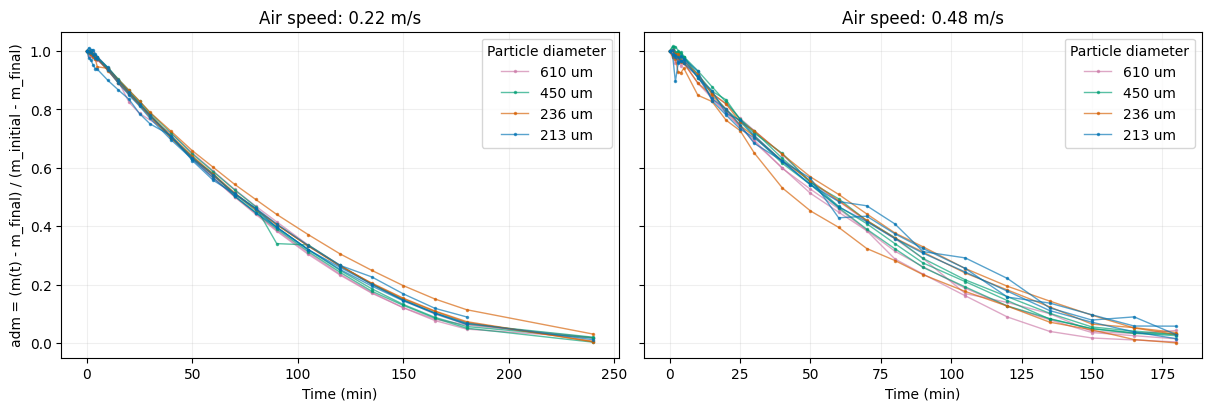

In [10]:
# display(experiments.head())
display(observations.head(10))

figure, axes = plt.subplots(
    1, 2, figsize=(12, 4), sharey=True, constrained_layout=True
)
colors = dict(
    zip(
        sorted(experiments["particle_diameter_m"].unique()),
        ["#0072B2", "#D55E00", "#009E73", "#CC79A7"],
    )
)
for axis, speed in zip(axes, sorted(experiments["air_speed_m_s"].unique())):
    for experiment_id, curve in training_view.loc[
        training_view["air_speed_m_s"].eq(speed)
    ].groupby("experiment_id", sort=False):
        diameter = curve["particle_diameter_m"].iloc[0]
        available = curve["target_available"]
        axis.plot(
            curve.loc[available, "time_s"] / 60,
            curve.loc[available, "adm_recomputed"],
            color=colors[diameter],
            alpha=0.65,
            linewidth=1,
            marker=".",
            markersize=3,
            label=f"{diameter * 1e6:.0f} um"
            if curve["replicate"].iloc[0] == 1
            else None,
        )
    axis.set(title=f"Air speed: {speed:g} m/s", xlabel="Time (min)")
    axis.grid(alpha=0.2)
    axis.legend(title="Particle diameter")
axes[0].set_ylabel("adm = (m(t) - m_final) / (m_initial - m_final)")
# plt.show()

legacy_pairs = observations[["tx_source", "legacy_adm_per_min"]].dropna()
print(
    "Workbook tx agrees with adm / time_min:",
    np.allclose(
        legacy_pairs["tx_source"],
        legacy_pairs["legacy_adm_per_min"],
        rtol=1e-5,
        atol=1e-6,
    ),
)


In [11]:
def make_training_tensors(frame: pd.DataFrame) -> dict[str, torch.Tensor]:
    """Normalize usable observations and give each replicate equal weight."""
    usable = frame.loc[frame["target_available"]].copy()
    if usable.empty:
        raise ValueError("No usable moisture observations.")
    features = np.column_stack(
        [
            usable["time_s"].to_numpy() / TIME_SCALE_S,
            np.log(
                usable["particle_diameter_m"].to_numpy() / DIAMETER_REFERENCE_M
            ),
            np.log(usable["air_speed_m_s"].to_numpy() / SPEED_REFERENCE_M_S),
        ]
    )
    targets = usable["adm_recomputed"].to_numpy()[:, None]
    if not np.isfinite(features).all() or not np.isfinite(targets).all():
        raise ValueError("Training features and targets must be finite.")
    curve_indices, curve_ids = pd.factorize(usable["experiment_id"], sort=True)
    counts = np.bincount(curve_indices)
    # More frequent measurements must not give a curve greater influence.
    weights = 1.0 / (len(curve_ids) * counts[curve_indices])
    return {
        # Sampling and quadrature inherit the split tensors' device.
        "features": torch.tensor(features, dtype=DTYPE, device=DEVICE),
        "adm": torch.tensor(targets, dtype=DTYPE, device=DEVICE),
        "curve_index": torch.tensor(
            curve_indices, dtype=torch.long, device=DEVICE
        ),
        "weights": torch.tensor(weights[:, None], dtype=DTYPE, device=DEVICE),
    }


# Split whole replicates before constructing targets to avoid temporal leakage.
# Conditions may overlap across splits; these are not held-out conditions.
curve_table = experiments.sort_values("experiment_id").reset_index(drop=True)
if len(curve_table) != 24 or curve_table["experiment_id"].duplicated().any():
    raise ValueError(
        "Expected 24 unique replicate curves for the 50/30/20 split."
    )
permutation = np.random.default_rng(5).permutation(len(curve_table))
split_indices = {
    "train": permutation[:12],
    "validation": permutation[12:19],
    "test": permutation[19:],
}
split_records = [
    {
        "experiment_id": curve_table.iloc[index]["experiment_id"],
        "split": split_name,
    }
    for split_name, indices in split_indices.items()
    for index in indices
]
split_assignment = pd.DataFrame(split_records)
training_view = observations.merge(
    experiments, on="experiment_id", validate="many_to_one"
).merge(split_assignment, on="experiment_id", validate="many_to_one")
splits = {
    split_name: make_training_tensors(
        training_view.loc[training_view["split"].eq(split_name)]
    )
    for split_name in split_indices
}

split_summary = (
    training_view.groupby("split")
    .agg(
        curves=("experiment_id", "nunique"),
        valid_measurements=("target_available", "sum"),
        air_speeds=("air_speed_m_s", "nunique"),
        diameters=("particle_diameter_m", "nunique"),
    )
    .reindex(["train", "validation", "test"])
)
display(split_summary)
print("Curve split proportions: 50% train, 30% validation, 20% test (seed=5).")
print(
    "Whole replicate curves are disjoint; "
    "every split covers both speeds and all four diameters."
)


,curves,valid_measurements,air_speeds,diameters
split,,,,
train,12,279,2,4
validation,7,163,2,4
test,5,118,2,4


Curve split proportions: 50% train, 30% validation, 20% test (seed=5).
Whole replicate curves are disjoint; every split covers both speeds and all four diameters.


In [12]:
class MissingPhysicsConfigError(ValueError):
    """Require explicit, provenance-bearing physics for real optimization."""


@dataclass(frozen=True)
class PhysicsConfig:
    """Explicit groups, keyed to curves/conditions; no inferred calibration.

    Scales optionally contain D_ref_m2_s, T0_K, T_air_K. Dimensionless
    groups and their normalization must be declared in provenance.
    """

    mode: str
    fo_ref: float
    fo_heat: float
    bih_by_condition: dict[str, float]
    ev_by_curve: dict[str, float]
    provenance: str
    scales: dict[str, float]

    def validate(self, curves: pd.DataFrame) -> None:
        """Reject missing curve coverage and inconsistent physical scales."""
        if (
            self.mode not in {"physical", "dimensionless"}
            or not self.provenance.strip()
        ):
            raise ValueError(
                "Declare physical/dimensionless mode and physics provenance."
            )
        if (
            not np.isfinite([self.fo_ref, self.fo_heat]).all()
            or min(self.fo_ref, self.fo_heat) <= 0
        ):
            raise ValueError("Foref and Foh must be finite and positive.")
        for column, mapping, allow_zero in [
            ("condition_id", self.bih_by_condition, False),
            ("experiment_id", self.ev_by_curve, True),
        ]:
            missing = set(curves[column]) - set(mapping)
            if missing:
                raise ValueError(
                    f"Missing {column} physics coverage: {sorted(missing)}"
                )
            values = np.asarray(list(mapping.values()), dtype=float)
            if (
                not np.isfinite(values).all()
                or (values < 0 if allow_zero else values <= 0).any()
            ):
                raise ValueError(f"Invalid groups for {column}.")
        if not all(np.isfinite(value) for value in self.scales.values()):
            raise ValueError("Physical export scales must be finite.")
        if "D_ref_m2_s" in self.scales and self.scales["D_ref_m2_s"] <= 0:
            raise ValueError("D_ref_m2_s must be positive.")
        temperatures = {"T0_K", "T_air_K"}
        if temperatures.intersection(
            self.scales
        ) and not temperatures.issubset(self.scales):
            raise ValueError("Supply both temperature scales or neither.")
        if (
            temperatures.issubset(self.scales)
            and not 0 < self.scales["T0_K"] < self.scales["T_air_K"]
        ):
            raise ValueError("Require T_air > T0 > 0 K.")
        if self.mode == "physical" and not {
            "D_ref_m2_s",
            *temperatures,
        }.issubset(self.scales):
            raise ValueError("Physical mode requires physical export scales.")


def physical_groups(
    curves: pd.DataFrame,
    *,
    d_ref_m2_s: float,
    alpha_m2_s: float,
    conductivity_w_m_k: float,
    h_by_condition: dict[str, float],
    latent_j_kg: float,
    cw0_by_curve: dict[str, float],
    initial_temperature_k: float,
    provenance: str,
) -> PhysicsConfig:
    """Convert physical properties; Cw0 is initial water mass per bed volume.

    Workbook masses alone cannot supply Cw0: measured bed volume (or area
    and verified depth) is required. h is evaluated at each condition's v.
    """
    positive = [
        d_ref_m2_s,
        alpha_m2_s,
        conductivity_w_m_k,
        latent_j_kg,
        initial_temperature_k,
        BED_DEPTH_M,
        TIME_SCALE_S,
    ]
    if not np.isfinite(positive).all() or min(positive) <= 0:
        raise ValueError(
            "Physical properties and scales must be finite and positive."
        )
    if not initial_temperature_k < AIR_TEMPERATURE_K:
        raise ValueError("Tair must exceed T0.")
    if set(curves["experiment_id"]) - set(cw0_by_curve):
        raise ValueError(
            "Missing Cw0_by_curve; supply measured volume-based water density."
        )
    if any(
        not np.isfinite(value) or value <= 0 for value in cw0_by_curve.values()
    ):
        raise ValueError("Cw0 must be finite and positive.")
    config = PhysicsConfig(
        "physical",
        d_ref_m2_s * TIME_SCALE_S / BED_DEPTH_M**2,
        alpha_m2_s * TIME_SCALE_S / BED_DEPTH_M**2,
        {
            key: value * BED_DEPTH_M / conductivity_w_m_k
            for key, value in h_by_condition.items()
        },
        {
            key: latent_j_kg
            * value
            * BED_DEPTH_M**2
            / (
                conductivity_w_m_k
                * TIME_SCALE_S
                * (AIR_TEMPERATURE_K - initial_temperature_k)
            )
            for key, value in cw0_by_curve.items()
        },
        provenance,
        {
            "D_ref_m2_s": d_ref_m2_s,
            "T0_K": initial_temperature_k,
            "T_air_K": AIR_TEMPERATURE_K,
        },
    )
    config.validate(curves)
    return config


def require_physics(
    config: PhysicsConfig | None, curves: pd.DataFrame
) -> PhysicsConfig:
    """Reject missing physics provenance or coverage before optimization."""
    if config is None:
        raise MissingPhysicsConfigError(
            "PHYSICS_CONFIG is missing: supply measured physical properties "
            "or explicitly declared dimensionless groups."
        )
    config.validate(curves)
    return config


class DryingPINN(nn.Module):
    """Map [z*, t*, v/vref, d/dref] to moisture and temperature states."""

    def __init__(
        self, *, device: torch.device = DEVICE, dtype: torch.dtype = DTYPE
    ) -> None:
        super().__init__()
        # Initialize on the target device, including checkpoint reconstruction.
        self.network = nn.Sequential(
            nn.Linear(4, 24, device=device, dtype=dtype),
            nn.Tanh(),
            nn.Linear(24, 24, device=device, dtype=dtype),
            nn.Tanh(),
            nn.Linear(24, 2, device=device, dtype=dtype),
        )
        self.diffusivity_network = nn.Sequential(
            nn.Linear(3, 16, device=device, dtype=dtype),
            nn.Tanh(),
            nn.Linear(16, 16, device=device, dtype=dtype),
            nn.Tanh(),
            nn.Linear(16, 1, device=device, dtype=dtype),
        )

    def forward(self, coordinates: torch.Tensor) -> torch.Tensor:
        # The time factor enforces adm=1 and T*=0 at t*=0 without an IC loss.
        raw = self.network(coordinates)
        time = coordinates[:, 1:2]
        return torch.cat([1 + time * raw[:, :1], time * raw[:, 1:2]], dim=1)

    def diffusivity(
        self, coordinates: torch.Tensor, temperature: torch.Tensor
    ) -> torch.Tensor:
        # Keep the temperature path so flux differentiation includes D_z.
        inputs = torch.cat(
            [coordinates[:, 3:4], coordinates[:, 2:3], temperature], dim=1
        )
        return (
            torch.nn.functional.softplus(self.diffusivity_network(inputs))
            + DIFFUSIVITY_FLOOR
        )


def state_coordinates(
    features: torch.Tensor, depth: torch.Tensor
) -> torch.Tensor:
    """Adapt legacy [t/tc, log(d/dref), log(v/vref)] to state coordinates."""
    return torch.cat(
        [
            depth,
            features[:, :1],
            features[:, 2:3].exp(),
            features[:, 1:2].exp(),
        ],
        dim=1,
    )


def bulk_adm(
    field: nn.Module, features: torch.Tensor, n_depth: int = 50
) -> torch.Tensor:
    """Use midpoint depth quadrature for the measured bulk moisture ratio."""
    if n_depth < 2 or features.ndim != 2 or features.shape[1] != 3:
        raise ValueError(
            "Expected >=2 midpoint depths and features with shape (N, 3)."
        )
    depths = (
        torch.arange(n_depth, dtype=features.dtype, device=features.device)
        + 0.5
    ) / n_depth
    repeated = features[:, None, :].expand(-1, n_depth, -1).reshape(-1, 3)
    coordinates = state_coordinates(
        repeated, depths.repeat(len(features))[:, None]
    )
    return (
        field(coordinates)[:, :1]
        .reshape(len(features), n_depth)
        .mean(dim=1, keepdim=True)
    )


def coordinate_gradient(
    values: torch.Tensor, coordinates: torch.Tensor
) -> torch.Tensor:
    """Retain the graph for second derivatives and parameter gradients."""
    return torch.autograd.grad(values.sum(), coordinates, create_graph=True)[0]


def predict_adm_and_dimensionless_rate(
    field: nn.Module, features: torch.Tensor
) -> tuple[torch.Tensor, torch.Tensor]:
    """Differentiate bulk moisture with respect to normalized time."""
    inputs = features.detach().clone().requires_grad_(True)
    prediction = bulk_adm(field, inputs)
    return prediction, -coordinate_gradient(prediction, inputs)[:, :1]


def predict_adm_and_rate(
    field: nn.Module, features: torch.Tensor
) -> tuple[torch.Tensor, torch.Tensor]:
    """Compatibility helper: positive-for-drying bulk rate in physical 1/s."""
    prediction, rate = predict_adm_and_dimensionless_rate(field, features)
    return prediction, rate / TIME_SCALE_S


def build_rate_intervals(frame: pd.DataFrame) -> pd.DataFrame:
    """Pair scheduled neighbours before filtering; never bridge bad rows."""
    records = []
    for experiment_id, curve in frame.groupby("experiment_id", sort=True):
        curve = curve.sort_values("time_s")
        if curve["time_s"].duplicated().any():
            raise ValueError("Duplicate scheduled time in rate construction.")
        rows = list(curve.to_dict("records"))
        for left, right in zip(rows[:-1], rows[1:]):
            if left["split"] != right["split"]:
                raise ValueError("A curve cannot cross splits.")
            if not (left["target_available"] and right["target_available"]):
                continue
            delta = (right["time_s"] - left["time_s"]) / TIME_SCALE_S
            values = [delta, left["adm_recomputed"], right["adm_recomputed"]]
            if not np.isfinite(values).all() or delta <= 0:
                raise ValueError(
                    "Rate endpoints must be finite and increasing."
                )
            # Positive means drying; retain negative rates from mass increases.
            rate = -(right["adm_recomputed"] - left["adm_recomputed"]) / delta
            records.append(
                {
                    "experiment_id": experiment_id,
                    "condition_id": left["condition_id"],
                    "split": left["split"],
                    "t_left": left["time_s"] / TIME_SCALE_S,
                    "t_right": right["time_s"] / TIME_SCALE_S,
                    "source_row_left": left["source_row"],
                    "source_row_right": right["source_row"],
                    "mr_left": left["adm_recomputed"],
                    "mr_right": right["adm_recomputed"],
                    "flags_left": left["quality_flags"],
                    "flags_right": right["quality_flags"],
                    "j_star": rate,
                    "negative_rate": rate < 0,
                    "log_d": np.log(
                        left["particle_diameter_m"] / DIAMETER_REFERENCE_M
                    ),
                    "log_v": np.log(
                        left["air_speed_m_s"] / SPEED_REFERENCE_M_S
                    ),
                }
            )
    result = pd.DataFrame(records)
    training_ids = set(frame.loc[frame["split"].eq("train"), "experiment_id"])
    covered = (
        set()
        if result.empty
        else set(result.loc[result["split"].eq("train"), "experiment_id"])
    )
    if training_ids - covered:
        raise ValueError(
            "Training curves have no valid rate interval: "
            f"{sorted(training_ids - covered)}"
        )
    if result.empty:
        raise ValueError("No valid scheduled rate intervals.")
    counts = result.groupby(["split", "experiment_id"])["j_star"].transform(
        "size"
    )
    curve_counts = result.groupby("split")["experiment_id"].transform(
        "nunique"
    )
    # Match the equal-curve moisture weighting within each split.
    result["weight"] = 1.0 / (counts * curve_counts)
    return result


def tensor_values(values: object, reference: torch.Tensor) -> torch.Tensor:
    """Match NumPy/pandas values to a reference tensor's dtype and device."""
    return torch.as_tensor(
        np.asarray(values, dtype=float),
        dtype=reference.dtype,
        device=reference.device,
    )


def differential_residuals(
    field: nn.Module, coordinates: torch.Tensor, config: PhysicsConfig
) -> dict[str, torch.Tensor]:
    """Compute conservative mass and heat residuals in scaled coordinates."""
    state = field(coordinates)
    moisture, temperature = state[:, :1], state[:, 1:2]
    moisture_grad = coordinate_gradient(moisture, coordinates)
    heat_grad = coordinate_gradient(temperature, coordinates)
    diffusivity = field.diffusivity(coordinates, temperature)
    # Differentiate the entire flux, preserving the local-temperature path.
    flux_gradient = coordinate_gradient(
        diffusivity * moisture_grad[:, :1], coordinates
    )[:, :1]
    heat_second = coordinate_gradient(heat_grad[:, :1], coordinates)[:, :1]
    return {
        "mass_pde": moisture_grad[:, 1:2] - config.fo_ref * flux_gradient,
        "heat_pde": heat_grad[:, 1:2] - config.fo_heat * heat_second,
        "moisture": moisture,
        "temperature": temperature,
        "moisture_z": moisture_grad[:, :1],
        "temperature_z": heat_grad[:, :1],
        "diffusivity": diffusivity,
    }


def surface_residuals(
    values: dict[str, torch.Tensor],
    forcing: torch.Tensor,
    bih: torch.Tensor,
    ev: torch.Tensor,
    fo_ref: float,
) -> dict[str, torch.Tensor]:
    """Balance outward drying flux and convective gain minus latent cooling."""
    return {
        "surface_mass": fo_ref * values["diffusivity"] * values["moisture_z"]
        + forcing,
        "surface_heat": values["temperature_z"]
        - bih * (1 - values["temperature"])
        + ev * forcing,
    }


def sample_collocation(
    intervals: pd.DataFrame, reference: torch.Tensor, seed: int, n_physics: int
) -> tuple[torch.Tensor, torch.Tensor, pd.DataFrame]:
    """Sample curves uniformly, then intervals, using training forcing only."""
    if (
        n_physics < 1
        or intervals.empty
        or not intervals["split"].eq("train").all()
    ):
        raise ValueError(
            "Collocation requires positive count and TRAINING intervals only."
        )
    generator = np.random.default_rng(seed)
    curve_ids = intervals["experiment_id"].unique()
    selected_ids = generator.choice(curve_ids, size=n_physics)
    selected = pd.DataFrame(
        [
            intervals.loc[intervals["experiment_id"].eq(curve_id)].iloc[
                generator.integers(
                    intervals["experiment_id"].eq(curve_id).sum()
                )
            ]
            for curve_id in selected_ids
        ]
    ).reset_index(drop=True)
    # Strictly interior fractions exclude t=0 and interval jumps.
    fraction = generator.uniform(1e-6, 1 - 1e-6, n_physics)
    time = (
        selected["t_left"].to_numpy()
        + fraction * (selected["t_right"] - selected["t_left"]).to_numpy()
    )
    features = tensor_values(
        np.column_stack([time, selected["log_d"], selected["log_v"]]),
        reference,
    )
    depth = tensor_values(
        generator.uniform(1e-6, 1 - 1e-6, (n_physics, 1)), reference
    )
    interior = state_coordinates(features, depth).requires_grad_(True)
    return interior, features, selected


def pinn_loss_terms(
    model: DryingPINN,
    batch: dict[str, torch.Tensor],
    intervals: pd.DataFrame,
    config: PhysicsConfig,
    seed: int = 42,
    n_physics: int = 128,
) -> dict[str, torch.Tensor]:
    """Combine data/rates, PDEs, boundary fluxes and moisture penalties."""
    interior, sampled_features, selected = sample_collocation(
        intervals, batch["features"], seed, n_physics
    )
    values = differential_residuals(model, interior, config)
    base = state_coordinates(
        sampled_features, torch.zeros_like(sampled_features[:, :1])
    ).requires_grad_(True)
    surface = state_coordinates(
        sampled_features, torch.ones_like(sampled_features[:, :1])
    ).requires_grad_(True)
    base_state = model(base)
    base_mass = coordinate_gradient(base_state[:, :1], base)[:, :1]
    base_heat = coordinate_gradient(base_state[:, 1:2], base)[:, :1]
    surface_values = differential_residuals(model, surface, config)
    forcing = tensor_values(selected["j_star"].to_numpy()[:, None], interior)
    bih = tensor_values(
        [[config.bih_by_condition[key]] for key in selected["condition_id"]],
        interior,
    )
    ev = tensor_values(
        [[config.ev_by_curve[key]] for key in selected["experiment_id"]],
        interior,
    )
    boundary = surface_residuals(
        surface_values, forcing, bih, ev, config.fo_ref
    )
    midpoint = (
        intervals["t_left"].to_numpy() + intervals["t_right"].to_numpy()
    ) / 2
    rate_features = tensor_values(
        np.column_stack([midpoint, intervals["log_d"], intervals["log_v"]]),
        interior,
    )
    _, rate = predict_adm_and_dimensionless_rate(model, rate_features)
    target_rate = tensor_values(
        intervals["j_star"].to_numpy()[:, None], interior
    )
    weights = tensor_values(intervals["weight"].to_numpy()[:, None], interior)
    predicted = bulk_adm(model, batch["features"])
    return {
        "data": (batch["weights"] * (predicted - batch["adm"]).square()).sum(),
        "rate": (weights * (rate - target_rate).square()).sum(),
        "mass_pde": values["mass_pde"].square().mean(),
        "heat_pde": values["heat_pde"].square().mean(),
        "base_mass": base_mass.square().mean(),
        "base_heat": base_heat.square().mean(),
        **{key: value.square().mean() for key, value in boundary.items()},
        "negative_moisture": torch.cat(
            [
                torch.relu(-values["moisture"]),
                torch.relu(-base_state[:, :1]),
                torch.relu(-surface_values["moisture"]),
            ]
        )
        .square()
        .mean(),
    }


rate_intervals = build_rate_intervals(training_view)
training_intervals = rate_intervals.loc[
    rate_intervals["split"].eq("train")
].copy()
print(
    f"Prepared {len(rate_intervals)} schedule-safe intervals; "
    f"{len(training_intervals)} training-only forcing intervals."
)
print(
    "Negative measured rates retained:",
    int(rate_intervals["negative_rate"].sum()),
)


Prepared 534 schedule-safe intervals; 265 training-only forcing intervals.
Negative measured rates retained: 21


,epoch,total,validation_mr_mse,validation_mr_rmse,validation_mr_mae,validation_mr_r2,train_accuracy,validation_accuracy,test_accuracy
0,1,334.851159,0.236683,0.486501,0.378036,-1.023298,0.258235,0.220497,0.246014
1,2,346.740932,0.225718,0.475098,0.369815,-0.929563,0.258235,0.220497,0.246014
2,3,399.007813,0.215008,0.463690,0.361580,-0.838012,0.261707,0.220497,0.262681
3,4,397.419820,0.204582,0.452307,0.353349,-0.748880,0.265179,0.220497,0.262681
4,5,420.061047,0.194441,0.440954,0.345127,-0.662190,0.265179,0.220497,0.271014
5,6,354.010648,0.184583,0.429631,0.336912,-0.577920,0.265179,0.220497,0.279348
6,7,313.156091,0.175002,0.418332,0.328696,-0.496013,0.268651,0.220497,0.279348
7,8,401.795024,0.165694,0.407056,0.320477,-0.416448,0.272274,0.220497,0.279348
8,9,381.690920,0.156653,0.395794,0.312247,-0.339157,0.272274,0.226449,0.279348
9,10,365.106512,0.147878,0.384550,0.304007,-0.264148,0.272274,0.232660,0.279348


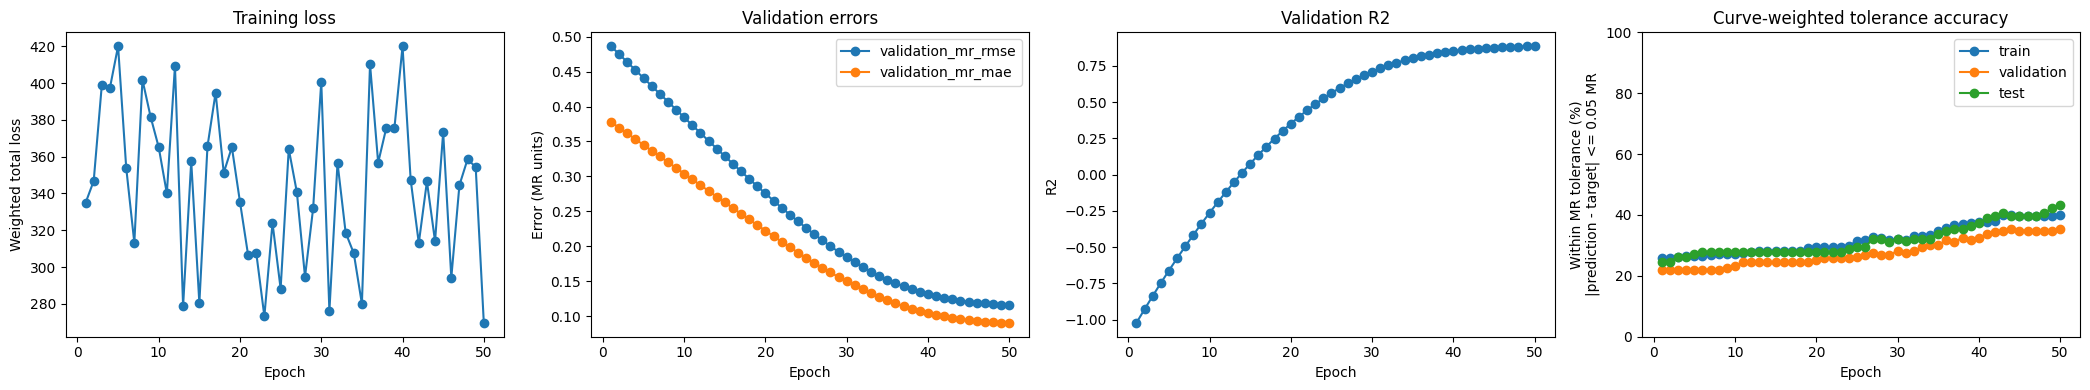

Selected epoch=50; validation MSE=0.0134083; held-out test MSE=0.0112406


In [13]:
@dataclass
class TrainingResult:
    """Keep the selected coupled checkpoint and its training-only support."""
    model: DryingPINN
    history: pd.DataFrame
    best_step: int
    validation_mse: float
    test_mse: float
    config: PhysicsConfig
    support: pd.DataFrame
    checkpoint: dict[str, torch.Tensor]
    seed: int
    learning_rate: float


def moisture_mse(model: nn.Module, batch: dict[str, torch.Tensor]) -> float:
    """Evaluate held-out moisture without measured flux as model input."""
    with torch.no_grad():
        value = (
            batch["weights"]
            * (bulk_adm(model, batch["features"]) - batch["adm"]).square()
        ).sum()
    if not torch.isfinite(value):
        raise FloatingPointError("Nonfinite held-out moisture error.")
    return value.item()


def moisture_tolerance_accuracy(
    model: nn.Module,
    batch: dict[str, torch.Tensor],
    tolerance: float,
) -> float:
    """Sum curve weights within inclusive MR tolerance, without gradients.

    This is a regression diagnostic, not classification accuracy. Existing
    observation weights must sum to one, giving each curve equal influence.
    Evaluation preserves the caller's model mode and keeps tensors on device.
    """
    if not np.isfinite(tolerance) or tolerance <= 0:
        raise ValueError("MR accuracy tolerance must be finite and positive.")
    was_training = model.training
    model.eval()
    try:
        with torch.no_grad():
            prediction = bulk_adm(model, batch["features"])
            target, weights = batch["adm"], batch["weights"]
            if (
                prediction.shape != target.shape
                or weights.shape != target.shape
            ):
                raise ValueError(
                    "MR predictions, targets and weights must align."
                )
            if not all(
                torch.isfinite(value).all().item()
                for value in (prediction, target, weights)
            ):
                raise FloatingPointError("Nonfinite MR accuracy input.")
            if (weights < 0).any() or not torch.isclose(
                weights.sum(), weights.new_tensor(1.0)
            ):
                raise ValueError(
                    "MR accuracy weights must be nonnegative and sum to one."
                )
            within = (prediction - target).abs().le(tolerance)
            accuracy = (weights * within).sum()
            # Bound only floating-point roundoff of normalized weight sums.
            return accuracy.clamp(0.0, 1.0).item()
    finally:
        model.train(was_training)


def moisture_metrics(
    model: nn.Module, batch: dict[str, torch.Tensor]
) -> dict[str, float]:
    """Compute curve-weighted regression metrics for moisture."""
    with torch.no_grad():
        prediction = bulk_adm(model, batch["features"])
        error = prediction - batch["adm"]
        weights = batch["weights"]
        mse = (weights * error.square()).sum()
        mae = (weights * error.abs()).sum()
        target_mean = (weights * batch["adm"]).sum()
        total_variance = (
            weights * (batch["adm"] - target_mean).square()
        ).sum()
        if total_variance <= torch.finfo(total_variance.dtype).eps:
            raise FloatingPointError(
                "R2 is undefined for constant validation moisture targets."
            )
        r2 = 1.0 - mse / total_variance
    values = {
        "validation_mr_mse": mse,
        "validation_mr_rmse": mse.sqrt(),
        "validation_mr_mae": mae,
        "validation_mr_r2": r2,
    }
    if not all(torch.isfinite(value).item() for value in values.values()):
        raise FloatingPointError("Nonfinite validation regression metric.")
    return {name: value.item() for name, value in values.items()}


def train_coupled(
    config: PhysicsConfig | None,
    batches: dict[str, dict[str, torch.Tensor]],
    intervals: pd.DataFrame,
    curves: pd.DataFrame,
    *,
    steps: int,
    learning_rate: float = lr,
    seed: int = TRAINING_SEED,
    n_physics: int = 128,
) -> TrainingResult:
    """Fit jointly; select only by validation MSE, never test monitoring.

    Post-update train/validation/test tolerance accuracies are diagnostics.
    Per-epoch test metrics must not be used for tuning or selection. The
    reported test MSE still belongs to the restored validation-selected state.
    """
    config = require_physics(config, curves)
    if steps < 1 or not np.isfinite(learning_rate) or learning_rate <= 0:
        raise ValueError("Training steps and learning rate must be positive.")
    train_ids = set(curves.loc[curves["split"].eq("train"), "experiment_id"])
    if (
        intervals.empty
        or not intervals["split"].eq("train").all()
        or set(intervals["experiment_id"]) != train_ids
    ):
        raise ValueError(
            "Optimizer forcing must cover exactly the training curves."
        )
    # Restore CPU and all CUDA RNG states after seeded model initialization.
    with torch.random.fork_rng(devices=list(range(torch.cuda.device_count()))):
        torch.manual_seed(seed)
        fitted = DryingPINN()
    parameter = next(fitted.parameters())
    local_batches = {
        name: {
            key: value.to(device=parameter.device)
            for key, value in batch.items()
        }
        for name, batch in batches.items()
    }
    optimizer = torch.optim.Adam(fitted.parameters(), lr=learning_rate)
    best_error = float("inf")
    best_state = {}
    best_step = 0
    history = []
    for step in range(1, steps + 1):
        fitted.train()
        optimizer.zero_grad(set_to_none=True)
        terms = pinn_loss_terms(
            fitted,
            local_batches["train"],
            intervals,
            config,
            seed=seed + step,
            n_physics=n_physics,
        )
        weighted = {
            key: LOSS_WEIGHTS[key] * value for key, value in terms.items()
        }
        total = torch.stack(list(weighted.values())).sum()
        if not all(
            torch.isfinite(value).item() for value in [*terms.values(), total]
        ):
            raise FloatingPointError(f"Nonfinite loss at step {step}.")
        total.backward()
        if not all(
            value.grad is not None and torch.isfinite(value.grad).all()
            for value in fitted.parameters()
        ):
            raise FloatingPointError(
                f"Missing/nonfinite joint gradients at step {step}."
            )
        optimizer.step()
        if not all(
            torch.isfinite(value).all() for value in fitted.parameters()
        ):
            raise FloatingPointError(f"Nonfinite parameters at step {step}.")
        fitted.eval()
        validation_metrics = moisture_metrics(
            fitted, local_batches["validation"]
        )
        validation = validation_metrics["validation_mr_mse"]
        # Test monitoring never enters losses or checkpoint selection.
        accuracies = {
            f"{name}_accuracy": moisture_tolerance_accuracy(
                fitted, local_batches[name], ACCURACY_TOLERANCE_MR
            )
            for name in ("train", "validation", "test")
        }
        history.append(
            {
                "step": step,
                "epoch": step,
                "collocation_seed": seed + step,
                "total": total.item(),
                **validation_metrics,
                **accuracies,
                **{f"raw_{key}": value.item() for key, value in terms.items()},
                **{
                    f"weighted_{key}": value.item()
                    for key, value in weighted.items()
                },
            }
        )
        # Clone tensors: later optimizer steps must not mutate this snapshot.
        if validation < best_error:
            best_error, best_step = validation, step
            best_state = {
                key: value.detach().clone()
                for key, value in fitted.state_dict().items()
            }
    fitted.load_state_dict(best_state)
    fitted.eval()
    test_error = moisture_mse(fitted, local_batches["test"])
    return TrainingResult(
        fitted,
        pd.DataFrame(history),
        best_step,
        best_error,
        test_error,
        config,
        intervals.copy(deep=True),
        best_state,
        seed,
        learning_rate,
    )


def export_diffusivity(
    result: TrainingResult, directory: Path
) -> pd.DataFrame:
    """Export training-support temperatures from the selected coupled state.

    Directory creation is exclusive, so existing artifacts are not replaced.
    Checkpoints include both networks; physical columns need supplied scales.
    """
    if directory.exists():
        raise FileExistsError(
            f"Refusing to overwrite export directory: {directory}"
        )
    if not result.support["split"].eq("train").all() or result.support.empty:
        raise ValueError(
            "Export support must contain training intervals only."
        )
    parameter = next(result.model.parameters())
    depth = (
        torch.arange(10, dtype=parameter.dtype, device=parameter.device) + 0.5
    ) / 10
    rows = result.support.loc[
        result.support.index.repeat(len(depth))
    ].reset_index(drop=True)
    features = tensor_values(
        np.column_stack(
            [
                (rows["t_left"] + rows["t_right"]) / 2,
                rows["log_d"],
                rows["log_v"],
            ]
        ),
        parameter,
    )
    coordinates = state_coordinates(
        features, depth.repeat(len(result.support))[:, None]
    )
    # Use the selected checkpoint even if the caller changed the live model.
    # Reconstruction must not advance CUDA RNGs or depend on the global device.
    with torch.random.fork_rng(devices=list(range(torch.cuda.device_count()))):
        selected_model = DryingPINN(
            device=parameter.device, dtype=parameter.dtype
        )
    selected_model.load_state_dict(result.checkpoint)
    selected_model.eval()
    with torch.no_grad():
        temperature = selected_model(coordinates)[:, 1:2]
        diffusivity = selected_model.diffusivity(coordinates, temperature)
    table = rows[
        [
            "experiment_id",
            "condition_id",
            "source_row_left",
            "source_row_right",
        ]
    ].copy()
    table["z_star"] = coordinates[:, 0].cpu().numpy()
    table["t_star"] = coordinates[:, 1].cpu().numpy()
    table["v_star"] = coordinates[:, 2].cpu().numpy()
    table["d_star"] = coordinates[:, 3].cpu().numpy()
    table["T_star"] = temperature[:, 0].cpu().numpy()
    table["D_star"] = diffusivity[:, 0].cpu().numpy()
    scales = result.config.scales
    if "D_ref_m2_s" in scales:
        table["D_m2_s"] = table["D_star"] * scales["D_ref_m2_s"]
    if {"T0_K", "T_air_K"}.issubset(scales):
        table["T_K"] = scales["T0_K"] + table["T_star"] * (
            scales["T_air_K"] - scales["T0_K"]
        )
    if not np.isfinite(table.select_dtypes(include="number").to_numpy()).all():
        raise FloatingPointError("Nonfinite export values.")
    metadata = {
        "physics": asdict(result.config),
        "checkpoint": "selected_coupled.pt",
        "selection": "minimum validation curve-weighted moisture MSE",
        "best_step": result.best_step,
        "seed": result.seed,
        "learning_rate": result.learning_rate,
        "validation_mse": result.validation_mse,
        "test_mse": result.test_mse,
        "loss_weights": LOSS_WEIGHTS,
        "dtype": str(parameter.dtype),
        "normalization": {
            "time_s": TIME_SCALE_S,
            "depth_m": BED_DEPTH_M,
            "speed_m_s": SPEED_REFERENCE_M_S,
            "diameter_m": DIAMETER_REFERENCE_M,
        },
        "support": (
            "Training interval midpoints and 10 midpoint depths; "
            "local model-predicted temperatures only."
        ),
        "training_curves": sorted(table["experiment_id"].unique().tolist()),
        "ranges": {
            name: [float(table[name].min()), float(table[name].max())]
            for name in [
                "z_star",
                "t_star",
                "v_star",
                "d_star",
                "T_star",
                "D_star",
            ]
        },
        "warning": (
            "Not scientific calibration; moisture alone does not uniquely "
            "identify temperature or D(T). Depth 0.05 m is the confirmed "
            "50 mm bed depth."
        ),
    }
    directory.mkdir(parents=True, exist_ok=False)
    table.to_csv(directory / "diffusivity_samples.csv", index=False)
    (directory / "metadata.json").write_text(
        json.dumps(metadata, indent=2, allow_nan=False), encoding="utf-8"
    )
    torch.save(result.checkpoint, directory / "selected_coupled.pt")
    result.history.to_csv(directory / "training_history.csv", index=False)
    return table


training_result = None
if RUN_TRAINING:
    if REQUIRE_CUDA_FOR_TRAINING and DEVICE.type != "cuda":
        raise RuntimeError(
            "CUDA is required for this experimental run; "
            "enable a CUDA notebook kernel."
        )
    if PHYSICS_CONFIG is None:
        _experimental_curves = experiments.merge(
            split_assignment, on="experiment_id", validate="one_to_one"
        )
        PHYSICS_CONFIG = PhysicsConfig(
            mode="dimensionless",
            fo_ref=0.005,
            fo_heat=1.0,
            bih_by_condition={
                str(key): 0.101
                for key in _experimental_curves["condition_id"].unique()
            },
            ev_by_curve={
                str(key): 10
                for key in _experimental_curves["experiment_id"].unique()
            },
            provenance=(
                "User-supplied exploratory dimensionless coefficients: "
                "Fo_ref=0.005, Fo_heat=1.0, Bi_h=0.102 for every condition, "
                "and Ev=10 for every curve. No calibration rationale was "
                "provided; results are exploratory "
                "and not physically calibrated."
            ),
            scales={},
        )
    training_result = train_coupled(
        PHYSICS_CONFIG,
        splits,
        training_intervals,
        experiments.merge(
            split_assignment, on="experiment_id", validate="one_to_one"
        ),
        steps=TRAINING_STEPS,
    )
    display(
        training_result.history[
            [
                "epoch",
                "total",
                "validation_mr_mse",
                "validation_mr_rmse",
                "validation_mr_mae",
                "validation_mr_r2",
                "train_accuracy",
                "validation_accuracy",
                "test_accuracy",
            ]
        ].style.format(precision=6)
    )
    figure, axes = plt.subplots(1, 4, figsize=(21, 4))
    axes[0].plot(
        training_result.history["epoch"],
        training_result.history["total"],
        marker="o",
    )
    axes[0].set(
        title="Training loss", xlabel="Epoch", ylabel="Weighted total loss"
    )
    for metric in ["validation_mr_rmse", "validation_mr_mae"]:
        axes[1].plot(
            training_result.history["epoch"],
            training_result.history[metric],
            marker="o",
            label=metric,
        )
    axes[1].set(
        title="Validation errors", xlabel="Epoch", ylabel="Error (MR units)"
    )
    axes[1].legend()
    axes[2].plot(
        training_result.history["epoch"],
        training_result.history["validation_mr_r2"],
        marker="o",
    )
    axes[2].set(title="Validation R2", xlabel="Epoch", ylabel="R2")
    for name in ("train", "validation", "test"):
        axes[3].plot(
            training_result.history["epoch"],
            100 * training_result.history[f"{name}_accuracy"],
            marker="o",
            label=name,
        )
    axes[3].set(
        title="Curve-weighted tolerance accuracy",
        xlabel="Epoch",
        ylabel=(
            "Within MR tolerance (%)\n"
            f"|prediction - target| <= {ACCURACY_TOLERANCE_MR:g} MR"
        ),
        ylim=(0, 100),
    )
    axes[3].legend()
    figure.tight_layout()
    plt.show()
    print(
        f"Selected epoch={training_result.best_step}; "
        f"validation MSE={training_result.validation_mse:.6g}; "
        f"held-out test MSE={training_result.test_mse:.6g}"
    )
if EXPORT_DIFFUSIVITY:
    if training_result is None:
        raise ValueError(
            "Export requires an explicitly trained, "
            "validation-selected training_result."
        )
    exported_diffusivity = export_diffusivity(
        training_result, EXPORT_DIRECTORY
    )


In [14]:
def check_moisture_tolerance_accuracy(device: torch.device) -> None:
    """Exercise manufactured regression accuracy without any optimization."""
    class ManufacturedMoisture(nn.Module):
        def forward(self, coordinates: torch.Tensor) -> torch.Tensor:
            assert not self.training and not torch.is_grad_enabled()
            return coordinates[:, 1:2]

    def tensor(values: list[list[float]]) -> torch.Tensor:
        return torch.tensor(values, dtype=DTYPE, device=device)

    # Two unequal-length curves carry 1/2 weight each, not 1/3 per point.
    # Binary-exact tolerance tests both signed boundary equalities reliably.
    tolerance = 0.125
    batch = {
        "features": tensor([[0.125, 0, 0], [-0.125, 0, 0], [0.25, 0, 0]]),
        "adm": tensor([[0.0], [0.0], [0.0]]),
        "weights": tensor([[0.5], [0.25], [0.25]]),
    }
    model = ManufacturedMoisture()
    assert moisture_tolerance_accuracy(model, batch, tolerance) == 0.75
    assert model.training
    model.eval()
    assert moisture_tolerance_accuracy(model, batch, tolerance) == 0.75
    assert not model.training
    assert moisture_tolerance_accuracy(model, batch, 0.25) == 1.0
    assert moisture_tolerance_accuracy(model, batch, 0.0625) == 0.0
    assert all(value.device == device for value in batch.values())
    assert all(value.grad is None for value in batch.values())
    for invalid in [0.0, -0.05, float("nan"), float("inf"), -float("inf")]:
        with np.testing.assert_raises(ValueError):
            moisture_tolerance_accuracy(model, batch, invalid)
    for key in ("features", "adm", "weights"):
        damaged = {name: value.clone() for name, value in batch.items()}
        damaged[key][0, 0] = float("nan")
        with np.testing.assert_raises(FloatingPointError):
            moisture_tolerance_accuracy(model, damaged, tolerance)
        assert not model.training
    for weights in (
        [[0.5], [0.5]], [[-0.5], [0.75], [0.75]], [[0.0]] * 3
    ):
        damaged = {**batch, "weights": tensor(weights)}
        with np.testing.assert_raises(ValueError):
            moisture_tolerance_accuracy(model, damaged, tolerance)
        assert not model.training


def run_design_checks() -> None:
    """Check data and physics, including a separate synthetic optimizer run.

    This function performs training and export I/O; it is not a lint check.
    Synthetic optimization leaves the real fitted weights untouched.
    """
    import tempfile

    expected_device = torch.empty(0, device=DEVICE).device
    check_moisture_tolerance_accuracy(expected_device)
    assert len(experiments) == 24
    assert (
        experiments.groupby("condition_id")["replicate"].nunique().eq(3).all()
    )
    assert not observations.duplicated(["experiment_id", "time_s"]).any()
    assert (
        training_view.loc[training_view["time_s"].eq(0), "adm_recomputed"]
        .eq(1)
        .all()
    )
    for source, computed in [
        ("u_source", "u_recomputed"),
        ("adm_source", "adm_recomputed"),
    ]:
        paired = observations[[source, computed]].dropna()
        np.testing.assert_allclose(
            paired[source], paired[computed], atol=1e-6, rtol=1e-5
        )
    assert not observations.loc[
        observations["quality_flags"].isin(["missing_mass", "below_dry_mass"]),
        "target_available",
    ].any()
    assert observations.loc[
        observations["quality_flags"].eq("mass_increase"), "target_available"
    ].all()
    np.testing.assert_allclose(
        legacy_pairs["tx_source"],
        legacy_pairs["legacy_adm_per_min"],
        atol=1e-6,
        rtol=1e-5,
    )
    assert (
        observations.loc[observations["time_s"].eq(0), "legacy_adm_per_min"]
        .isna()
        .all()
    )
    assert split_assignment.groupby("split").size().to_dict() == {
        "train": 12,
        "validation": 7,
        "test": 5,
    }
    assert not split_assignment["experiment_id"].duplicated().any()
    for name, batch in splits.items():
        view = training_view.loc[training_view["split"].eq(name)]
        assert (
            view["air_speed_m_s"].nunique() == 2
            and view["particle_diameter_m"].nunique() == 4
        )
        assert (
            torch.isfinite(batch["features"]).all()
            and torch.isfinite(batch["adm"]).all()
        )
        # Resolve unindexed 'cuda' to the actual tensor device, e.g. cuda:0.
        assert all(value.device == expected_device for value in batch.values())
        torch.testing.assert_close(
            batch["weights"].sum(), batch["weights"].new_tensor(1.0)
        )
        for curve_index in batch["curve_index"].unique():
            torch.testing.assert_close(
                batch["weights"][batch["curve_index"].eq(curve_index)].sum(),
                batch["weights"].new_tensor(
                    1 / len(batch["curve_index"].unique())
                ),
            )
        rates = rate_intervals.loc[rate_intervals["split"].eq(name)]
        np.testing.assert_allclose(
            rates.groupby("experiment_id")["weight"].sum(),
            1 / view["experiment_id"].nunique(),
        )
    assert set(training_intervals["experiment_id"]) == set(
        split_assignment.loc[
            split_assignment["split"].eq("train"), "experiment_id"
        ]
    )
    for row in rate_intervals.to_dict("records"):
        schedule = training_view.loc[
            training_view["experiment_id"].eq(row["experiment_id"])
        ].sort_values("time_s")
        positions = schedule["source_row"].tolist()
        assert (
            positions.index(row["source_row_right"])
            == positions.index(row["source_row_left"]) + 1
        )
    assert (
        rate_intervals.loc[rate_intervals["negative_rate"], "j_star"]
        .lt(0)
        .all()
    )
    with np.testing.assert_raises(ValueError):
        make_training_tensors(training_view.iloc[:0])
    with np.testing.assert_raises(ValueError):
        parse_drying_workbook({})
    with np.testing.assert_raises(ValueError):
        parse_drying_workbook({"invalid": next(iter(raw_sheets.values()))})
    first_sheet = next(iter(raw_sheets))
    for row_index, column_index, replacement in [
        (7, 0, 0),
        (5, 1, "unexpected"),
        (30, 2, 100),
        (1, 1, "unknown"),
    ]:
        modified = {
            name: frame.copy(deep=True) for name, frame in raw_sheets.items()
        }
        modified[first_sheet].iloc[row_index, column_index] = replacement
        with np.testing.assert_raises(ValueError):
            parse_drying_workbook(modified)

    synthetic_records = []
    for name in ["train", "validation", "test"]:
        for index, time in enumerate([0.0, 0.3, 0.7]):
            synthetic_records.append(
                {
                    "experiment_id": name,
                    "condition_id": "synthetic",
                    "split": name,
                    "time_s": time * TIME_SCALE_S,
                    "adm_recomputed": np.exp(-time),
                    "particle_diameter_m": DIAMETER_REFERENCE_M,
                    "air_speed_m_s": SPEED_REFERENCE_M_S,
                    "target_available": True,
                    "quality_flags": "",
                    "source_row": index + 1,
                }
            )
    synthetic = pd.DataFrame(synthetic_records)
    curves = synthetic[
        ["experiment_id", "condition_id", "split"]
    ].drop_duplicates()
    config = PhysicsConfig(
        "dimensionless",
        0.2,
        0.3,
        {"synthetic": 0.4},
        {name: 0.1 for name in curves["experiment_id"]},
        "NONPHYSICAL synthetic smoke groups; "
        "z/L, t/tc, normalized temperature only",
        {},
    )
    config.validate(curves)
    with np.testing.assert_raises(MissingPhysicsConfigError):
        require_physics(None, curves)
    for invalid in [
        PhysicsConfig(
            "dimensionless",
            -1,
            0.3,
            {"synthetic": 0.4},
            config.ev_by_curve,
            "test",
            {},
        ),
        PhysicsConfig(
            "dimensionless", 0.2, 0.3, {}, config.ev_by_curve, "test", {}
        ),
        PhysicsConfig(
            "dimensionless", 0.2, 0.3, {"synthetic": 0.4}, {}, "test", {}
        ),
        PhysicsConfig(
            "dimensionless",
            0.2,
            0.3,
            {"synthetic": 0.4},
            config.ev_by_curve,
            "",
            {},
        ),
        PhysicsConfig(
            "dimensionless",
            0.2,
            0.3,
            {"synthetic": np.nan},
            config.ev_by_curve,
            "test",
            {},
        ),
    ]:
        with np.testing.assert_raises(ValueError):
            invalid.validate(curves)
    physical = physical_groups(
        curves,
        d_ref_m2_s=1e-10,
        alpha_m2_s=1e-7,
        conductivity_w_m_k=0.2,
        h_by_condition={"synthetic": 10.0},
        latent_j_kg=2e6,
        cw0_by_curve={name: 100.0 for name in curves["experiment_id"]},
        initial_temperature_k=300.0,
        provenance="Synthetic conversion test, NOT calibration",
    )
    np.testing.assert_allclose(
        physical.fo_ref, 1e-10 * TIME_SCALE_S / BED_DEPTH_M**2
    )
    np.testing.assert_allclose(
        physical.fo_heat, 1e-7 * TIME_SCALE_S / BED_DEPTH_M**2
    )
    np.testing.assert_allclose(
        physical.bih_by_condition["synthetic"], 10 * BED_DEPTH_M / 0.2
    )
    np.testing.assert_allclose(
        physical.ev_by_curve["train"],
        2e6
        * 100
        * BED_DEPTH_M**2
        / (0.2 * TIME_SCALE_S * (AIR_TEMPERATURE_K - 300)),
    )
    with np.testing.assert_raises(ValueError):
        physical_groups(
            curves,
            d_ref_m2_s=1e-10,
            alpha_m2_s=1e-7,
            conductivity_w_m_k=0.2,
            h_by_condition={"synthetic": 10.0},
            latent_j_kg=2e6,
            cw0_by_curve={},
            initial_temperature_k=300.0,
            provenance="test",
        )

    synthetic_rates = build_rate_intervals(synthetic)
    forcing = synthetic_rates.loc[synthetic_rates["split"].eq("train")].copy()
    damaged = synthetic.copy()
    damaged.loc[
        (damaged["split"] == "train") & (damaged["source_row"] == 2),
        "target_available",
    ] = False
    with np.testing.assert_raises(ValueError):
        build_rate_intervals(damaged)
    increasing = synthetic.copy()
    increasing.loc[
        (increasing["split"] == "train") & (increasing["source_row"] == 2),
        "adm_recomputed",
    ] = 1.1
    assert (
        build_rate_intervals(increasing)
        .query("split == 'train'")["negative_rate"]
        .any()
    )
    batches = {
        name: make_training_tensors(synthetic.loc[synthetic["split"].eq(name)])
        for name in ["train", "validation", "test"]
    }
    reference = batches["train"]["features"]
    interior, sampled, selected = sample_collocation(forcing, reference, 43, 8)
    # NumPy/pandas comparisons are reporting boundaries, not model inputs.
    assert (
        (interior[:, 1].detach().cpu().numpy() > selected["t_left"].to_numpy())
        & (
            interior[:, 1].detach().cpu().numpy()
            < selected["t_right"].to_numpy()
        )
    ).all()
    assert interior.device == sampled.device == reference.device
    assert all(
        value.device == reference.device
        for batch in batches.values()
        for value in batch.values()
    )
    assert selected["split"].eq("train").all()
    other, _, _ = sample_collocation(forcing, reference, 44, 8)
    assert not torch.equal(other, interior)
    with np.testing.assert_raises(ValueError):
        sample_collocation(synthetic_rates, reference, 42, 8)
    with np.testing.assert_raises(ValueError):
        bulk_adm(nn.Identity(), reference, 1)
    adapted = state_coordinates(
        reference.new_tensor([[0.2, np.log(2), np.log(3)]]),
        reference.new_tensor([[0.4]]),
    )
    torch.testing.assert_close(
        adapted, reference.new_tensor([[0.4, 0.2, 3.0, 2.0]])
    )

    class ManufacturedFlux(nn.Module):
        def forward(self, coordinates: torch.Tensor) -> torch.Tensor:
            depth, time = coordinates[:, :1], coordinates[:, 1:2]
            return torch.cat(
                [time + depth.square(), depth + 0 * time.square()], dim=1
            )

        def diffusivity(
            self, coordinates: torch.Tensor, temperature: torch.Tensor
        ) -> torch.Tensor:
            return 1 + temperature

    manufactured = differential_residuals(ManufacturedFlux(), interior, config)
    torch.testing.assert_close(
        manufactured["mass_pde"], 1 - config.fo_ref * (2 + 4 * interior[:, :1])
    )
    torch.testing.assert_close(
        manufactured["heat_pde"], torch.zeros_like(interior[:, :1])
    )

    class ManufacturedHeat(ManufacturedFlux):
        def forward(self, coordinates: torch.Tensor) -> torch.Tensor:
            depth, time = coordinates[:, :1], coordinates[:, 1:2]
            return torch.cat(
                [time + depth.square(), time + depth.square()], dim=1
            )

    heat = differential_residuals(ManufacturedHeat(), interior, config)
    torch.testing.assert_close(
        heat["heat_pde"],
        torch.full_like(interior[:, :1], 1 - 2 * config.fo_heat),
    )
    for depth in [0.0, 1.0]:
        boundary_coordinates = state_coordinates(
            sampled, torch.full_like(sampled[:, :1], depth)
        ).requires_grad_(True)
        values = differential_residuals(
            ManufacturedHeat(), boundary_coordinates, config
        )
        torch.testing.assert_close(
            values["moisture_z"],
            torch.full_like(values["moisture_z"], 2 * depth),
        )
        torch.testing.assert_close(
            values["temperature_z"],
            torch.full_like(values["temperature_z"], 2 * depth),
        )
        if depth == 1:
            flux = torch.full_like(values["temperature"], 0.7)
            boundary = surface_residuals(
                values,
                flux,
                0.4 * torch.ones_like(flux),
                0.1 * torch.ones_like(flux),
                0.2,
            )
            torch.testing.assert_close(
                boundary["surface_mass"], 0.2 * values["diffusivity"] * 2 + 0.7
            )
            torch.testing.assert_close(
                boundary["surface_heat"],
                2 - 0.4 * (1 - values["temperature"]) + 0.07,
            )

    class ExponentialField(nn.Module):
        def forward(self, coordinates: torch.Tensor) -> torch.Tensor:
            return (
                torch.exp(-2 * coordinates[:, 1:2])
                + 0 * coordinates[:, :1].square()
            )

    class QuadraticField(nn.Module):
        def forward(self, coordinates: torch.Tensor) -> torch.Tensor:
            return coordinates[:, :1].square()

    expected = torch.exp(-2 * reference[:, :1])
    prediction, rate = predict_adm_and_rate(ExponentialField(), reference)
    _, dimensionless_rate = predict_adm_and_dimensionless_rate(
        ExponentialField(), reference
    )
    torch.testing.assert_close(prediction, expected)
    torch.testing.assert_close(rate, 2 * expected / TIME_SCALE_S)
    torch.testing.assert_close(rate * 60, 2 * expected / (TIME_SCALE_S / 60))
    torch.testing.assert_close(dimensionless_rate, rate * TIME_SCALE_S)
    torch.testing.assert_close(
        bulk_adm(QuadraticField(), reference),
        torch.full_like(expected, 1 / 3 - 1 / (12 * 50**2)),
    )

    # Native initialization must preserve the caller's CPU and CUDA RNG states.
    cpu_rng = torch.get_rng_state()
    cuda_rngs = torch.cuda.get_rng_state_all()
    with torch.random.fork_rng(devices=list(range(torch.cuda.device_count()))):
        torch.manual_seed(42)
        probe = DryingPINN()
    assert torch.equal(torch.get_rng_state(), cpu_rng)
    assert all(
        torch.equal(current, saved)
        for current, saved in zip(torch.cuda.get_rng_state_all(), cuda_rngs)
    )
    initial = interior.detach().clone()
    initial[:, 1] = 0
    torch.testing.assert_close(
        probe(initial),
        initial.new_tensor([[1.0, 0.0]]).expand(len(initial), -1),
    )
    local_temperature = probe(interior)[:, 1:2]
    local_diffusivity = probe.diffusivity(interior, local_temperature)
    assert (local_diffusivity >= DIFFUSIVITY_FLOOR).all()
    temperature_path = torch.autograd.grad(
        local_diffusivity.sum(), local_temperature, retain_graph=True
    )[0]
    assert temperature_path.abs().sum() > 0
    mass_only = (
        differential_residuals(probe, interior, config)["mass_pde"]
        .square()
        .mean()
    )
    mass_only.backward()
    assert probe.network[-1].weight.grad[1].abs().sum() > 0
    assert all(
        value.grad is not None and torch.isfinite(value.grad).all()
        for value in probe.diffusivity_network.parameters()
    )
    probe.zero_grad(set_to_none=True)
    terms = pinn_loss_terms(
        probe, batches["train"], forcing, config, n_physics=8
    )
    assert set(terms) == set(LOSS_WEIGHTS)
    assert all(value.device == reference.device for value in terms.values())
    sum(LOSS_WEIGHTS[key] * value for key, value in terms.items()).backward()
    assert all(
        value.grad is not None and torch.isfinite(value.grad).all()
        for value in probe.parameters()
    )
    assert all(
        value.dtype == DTYPE and value.device == reference.device
        for value in probe.parameters()
    )
    quadrature_difference = (
        (
            bulk_adm(probe, splits["train"]["features"], 50)
            - bulk_adm(probe, splits["train"]["features"], 100)
        )
        .abs()
        .max()
        .item()
    )
    assert quadrature_difference < 1e-3
    initial_error = (
        (probe(initial) - initial.new_tensor([[1.0, 0.0]])).abs().max().item()
    )
    assert initial_error == 0

    before_smoke = {
        key: value.detach().clone()
        for key, value in probe.state_dict().items()
    }
    result = train_coupled(
        config, batches, forcing, curves, steps=3, n_physics=8
    )
    assert (
        len(result.history) == 3
        and result.history["collocation_seed"].is_unique
    )
    assert {
        "epoch",
        "total",
        "validation_mr_mse",
        "validation_mr_rmse",
        "validation_mr_mae",
        "validation_mr_r2",
        "train_accuracy",
        "validation_accuracy",
        "test_accuracy",
    }.issubset(result.history.columns)
    assert np.isfinite(result.history.to_numpy()).all()
    for name in ("train", "validation", "test"):
        assert result.history[f"{name}_accuracy"].between(0, 1).all()
    np.testing.assert_allclose(
        result.test_mse, moisture_mse(result.model, batches["test"])
    )
    assert result.best_step == int(
        result.history.loc[
            result.history["validation_mr_mse"].idxmin(), "step"
        ]
    )
    assert result.validation_mse == result.history["validation_mr_mse"].min()
    assert all(
        torch.equal(value, result.checkpoint[key])
        for key, value in result.model.state_dict().items()
    )
    assert all(
        value.device == reference.device
        for value in result.checkpoint.values()
    )
    assert all(
        torch.equal(value, before_smoke[key])
        for key, value in probe.state_dict().items()
    )
    assert any(
        not torch.equal(result.checkpoint[key], before_smoke[key])
        for key in before_smoke
        if key.startswith("network.")
    )
    assert any(
        not torch.equal(result.checkpoint[key], before_smoke[key])
        for key in before_smoke
        if key.startswith("diffusivity_network.")
    )
    with np.testing.assert_raises(MissingPhysicsConfigError):
        train_coupled(None, batches, forcing, curves, steps=1)
    with np.testing.assert_raises(ValueError):
        train_coupled(config, batches, synthetic_rates, curves, steps=1)
    with tempfile.TemporaryDirectory() as temporary:
        directory = Path(temporary) / "export"
        exported = export_diffusivity(result, directory)
        assert set(exported["experiment_id"]) == {"train"}
        assert "D_m2_s" not in exported and "T_K" not in exported
        saved = torch.load(
            directory / "selected_coupled.pt",
            map_location=reference.device,
            weights_only=True,
        )
        assert all(
            torch.equal(value, saved[key])
            for key, value in result.checkpoint.items()
        )
        metadata = json.loads(
            (directory / "metadata.json").read_text(encoding="utf-8")
        )
        assert metadata["best_step"] == result.best_step
        pd.testing.assert_frame_equal(
            pd.read_csv(directory / "diffusivity_samples.csv"),
            exported,
            check_dtype=False,
        )
        with np.testing.assert_raises(FileExistsError):
            export_diffusivity(result, directory)
        result.config = physical
        physical_export = export_diffusivity(
            result, Path(temporary) / "physical_export"
        )
        np.testing.assert_allclose(
            physical_export["D_m2_s"], physical_export["D_star"] * 1e-10
        )
        np.testing.assert_allclose(
            physical_export["T_K"],
            300 + physical_export["T_star"] * (AIR_TEMPERATURE_K - 300),
        )
    print(
        "PASS: preserved data/splits; full D_z flux; heat/base/surface signs; "
        f"hard IC error={initial_error}; positive D and coupled gradients."
    )
    print(
        "PASS: scheduled gaps, negative rates, curve weights, "
        "train-only forcing, physical/rate conversions; "
        "quadrature 50 vs 100 max "
        f"difference={quadrature_difference:.3g}."
    )
    print(
        "PASS: 3 synthetic Adam steps, finite joint gradients/parameters, "
        "fresh seeds, cloned selected checkpoint, selected-state test MSE "
        "and export round trip. "
        f"Best synthetic step={result.best_step}."
    )
    print(
        "Synthetic checks are isolated from the experimental training result."
    )


run_design_checks()


PASS: preserved data/splits; full D_z flux; heat/base/surface signs; hard IC error=0.0; positive D and coupled gradients.
PASS: scheduled gaps, negative rates, curve weights, train-only forcing, physical/rate conversions; quadrature 50 vs 100 max difference=3.29e-07.
PASS: 3 synthetic Adam steps, finite joint gradients/parameters, fresh seeds, cloned selected checkpoint, selected-state test MSE and export round trip. Best synthetic step=3.
Synthetic checks are isolated from the experimental training result.


## Strategy B: Configuration, Runs, And Limits

- Cell 1 selects CUDA when available and is configured for a five-epoch exploratory training run; training requires a CUDA kernel. The supplied groups are Fo_ref=Fo_heat=1.0, Bi_h=0.101 for every condition and Ev=1.0 for every curve. Cells 2-4 preserve workbook parsing, plots, legacy tensors and seed-5 whole-curve splits.
- Cell 5 defines the coupled networks, coordinate adapter, conservative residuals, schedule-safe rate intervals and `PhysicsConfig`. After this cell, supply a provenance-bearing explicit dimensionless configuration or use `physical_groups` with measured properties. Missing calibration does not block preparation; `MissingPhysicsConfigError` blocks actual training without config.
- Cell 6 defines `train_coupled` and `export_diffusivity`. The configured run reports weighted loss and validation MSE, RMSE, MAE and R2 by epoch, with a plot. Curve-weighted tolerance accuracy sums the existing observation weights where `abs(bulk_adm - adm) <= ACCURACY_TOLERANCE_MR` (default 0.05 MR, finite and positive). This is a regression tolerance, not classification accuracy. History/table columns `train_accuracy`, `validation_accuracy`, `test_accuracy` are fractions; the three-line epoch panel shows 0-100%. All are evaluated after each update in eval/no_grad on device. Per-epoch test accuracy is monitoring only and must not be used for tuning or selection; checkpoints still minimize validation MSE, and reported test MSE uses the restored selected state. Export remains off by default; no PySR fitting is performed.
- Cell 7 runs deterministic manufactured checks and only three synthetic optimizer steps with explicitly nonphysical groups. Synthetic models and temporary exports are isolated from real training.

The state is `[z*, t*, v/vref, d/dref] -> [rho*, T*]`. The diffusivity network takes `[d/dref, v/vref, local predicted T*]`; local temperature remains attached to autograd. Rate supervision uses the midpoint AD rate as an approximation to an interval-average secant. Only training intervals force boundaries; validation/test inference never uses measured fluxes.

**Bed geometry:** `BED_DEPTH_M=0.05` means the confirmed 50 mm experimental depth. The supplied dimensionless groups are exploratory user inputs with no stated calibration rationale; results are not scientifically calibrated. Physical conversion requires supplied temperature and transport properties plus initial water density based on a measured volume. Moisture-only data do not uniquely identify temperature or diffusivity. Dimensionless scaling does not bound derivatives or justify equal physics weights.

See [loss definitions](../docs/on_loss.md) and [configuration/API usage](../docs/on_nn_design.md).